<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

**Worker: [vgi-cbor](https://github.com/Query-farm/vgi-cbor)**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-cbor/blob/main/notebooks/02_json_equality_is_not_cbor_identity.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-cbor/blob/main/notebooks/README.md)

# 02 · JSON equality is not CBOR identity

**Can a convenient JSON view serve as a faithful archive of CBOR input?**
We will compare eight authored items in four deliberate pairs. A byte string and
a text string can project to the same JSON; so can a semantic tag and its inner
value. Integer and text map keys can even collide after projection. A fourth pair
changes only map insertion order, giving a contrasting case for canonical encoding.

The bytes are synthetic examples, not credentials or captured traffic. Four
separate quality controls remain outside the identity study. This notebook makes
an in-memory archive comparison; it writes no token or remote storage system.

## Choose the derived archive representation

With **`REBUILD_FROM_JSON = False`**, use the worker's default core canonical
encoding of each original item. The focused experiment switches only to **True**,
which projects the input to JSON and rebuilds CBOR from that JSON. Original bytes
remain retained in both runs. Core canonical equality is a defined comparison for
these cases, not permission to alter signed bytes or a universal semantic-equivalence test.

In [1]:
REBUILD_FROM_JSON = False

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.7":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.7"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme

check_runtime()
prepare("cbor")
import cbor_example as example

example.validate_rebuild(REBUILD_FROM_JSON)
session = connect(globals())
theme()

## Attach the released local codec and retain the authored bytes

The literal release location downloads and verifies the native worker. All calls
below operate on bytes in memory. The labels explain the authored pairs; the
worker supplies the actual projections, diagnostics and canonical encodings.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'cbor' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-cbor@v0.7.1');
CREATE TABLE samples AS
SELECT id,pair_id,pair_label,label,from_hex(encoded) AS source
FROM (VALUES
 (1,1,'Byte string vs text','Byte string','420102'),
 (2,1,'Byte string vs text','Text string','63415149'),
 (3,2,'Tag vs bare integer','Epoch tag','c101'),
 (4,2,'Tag vs bare integer','Bare integer','01'),
 (5,3,'Integer vs text map keys','Mixed key types','a20101613102'),
 (6,3,'Integer vs text map keys','Collapsed text key','a1613102'),
 (7,4,'Map insertion order','Integer key first','a21903e801616202'),
 (8,4,'Map insertion order','Text key first','a26162021903e801')
) t(id,pair_id,pair_label,label,encoded);
CREATE TABLE controls AS
SELECT label,from_hex(encoded) AS source
FROM (VALUES ('Truncated item','4201'),('Duplicate key','a201010102'),
             ('Trailing bytes','0102'),('Missing input',NULL)) t(label,encoded);

,Count


## A parseable item is not the whole quality contract

`is_valid` checks that the input is exactly one parseable CBOR item; duplicate map
keys are tolerated there. `well_formed` adds the worker's duplicate-key check and
a reason. Inspect both before treating successful JSON output as evidence of
acceptable input. These are codec checks, not an application's schema or trust policy.

In [5]:
%%sql controls_frame <<
SELECT label,cbor.main.is_valid(source) AS single_item_valid,
       cbor.main.well_formed(source).ok AS strict_ok,
       cbor.main.well_formed(source).kind AS reason,
       cbor.main.to_json(source) AS json_view
FROM controls ORDER BY label;

In [6]:
example.control_finding(controls_frame)

,label,single_item_valid,strict_ok,reason,json_view
0,Duplicate key,True,False,duplicate-key,"{""1"":2}"
1,Missing input,<NA>,<NA>,None,None
2,Trailing bytes,False,False,trailing-bytes,None
3,Truncated item,False,False,truncated,None


The duplicate-key control is **one parseable item** but fails the worker's stricter map-key check. Truncation and trailing bytes fail the single-item check; NULL stays unknown. A non-NULL JSON projection is therefore not a substitute for the input-quality decision. The eight identity-study items pass both checks and stay separate from these four controls.

## Compare JSON with a type-preserving diagnostic view

Materialize the projections before using them elsewhere. `decode(...,'struct')`
accepts that mode name but this release still returns JSON text in a VARCHAR
column. It has the same projection losses as `to_json`; the mode name does not
make the result a lossless typed object. The diagnostic notation exposes tags,
byte strings and non-text keys that the JSON view hides.

In [7]:
%%sql
CREATE TABLE projected AS
SELECT *,cbor.main.to_json(source) AS json_view,
       cbor.main.decode(source,'struct') AS decode_struct,
       cbor.main.diagnostic(source) AS diagnostic,
       cbor.main.canonical(source) AS core_bytes
FROM samples;

,Count


In [8]:
%%sql projection <<
SELECT id,label,json_view,decode_struct,typeof(decode_struct) AS decode_type,diagnostic
FROM projected ORDER BY id;

In [9]:
example.projection_finding(projection)

,id,label,json_view,decode_struct,decode_type,diagnostic
0,1,Byte string,"""AQI""","""AQI""",VARCHAR,h'0102'
1,2,Text string,"""AQI""","""AQI""",VARCHAR,"""AQI"""
2,3,Epoch tag,1,1,VARCHAR,1(1)
3,4,Bare integer,1,1,VARCHAR,1
4,5,Mixed key types,"{""1"":2}","{""1"":2}",VARCHAR,"{1: 1, ""1"": 2}"
5,6,Collapsed text key,"{""1"":2}","{""1"":2}",VARCHAR,"{""1"": 2}"
6,7,Integer key first,"{""1000"":1,""b"":2}","{""1000"":1,""b"":2}",VARCHAR,"{1000: 1, ""b"": 2}"
7,8,Text key first,"{""1000"":1,""b"":2}","{""1000"":1,""b"":2}",VARCHAR,"{""b"": 2, 1000: 1}"


All eight rows return **the same JSON text from `to_json` and `decode(...,'struct')`**. Despite that mode name, this release returns VARCHAR; it does not restore a typed CBOR value. The diagnostic column distinguishes byte strings from text, tags from bare values, and integer map keys from text keys. Keep original bytes when those distinctions matter.

## Recover tag context before discarding it

Tag 1 identifies an epoch-based date/time representation; the untagged integer
has no such marker. `tags` lists tag numbers, paths and projected values. `untag`
collects values under a requested tag into a JSON array; an absent tag produces
an empty array. Neither operation rewrites the original bytes or validates a time source.

[RFC 8949 §3.4.2](https://www.rfc-editor.org/rfc/rfc8949.html#section-3.4.2) defines tag 1; its JSON conversion discussion explains why a projection cannot preserve every CBOR type.

In [10]:
%%sql tag_rows <<
SELECT label,diagnostic,cbor.main.tags(source) AS tag_locations,
       cbor.main.untag(source,1) AS values_under_tag1
FROM projected WHERE pair_id=2 ORDER BY id;

In [11]:
example.tag_finding(tag_rows)

,label,diagnostic,tag_locations,values_under_tag1
0,Epoch tag,1(1),"[{'tag': 1, 'path': '$', 'value': '1'}]",[1]
1,Bare integer,1,[],[]


Only the tagged item reports **tag 1 at `$`**, and `untag(...,1)` returns **`[1]`** for it versus **`[]`** for the bare integer. `untag` returns JSON values found under a tag; it does not return a rewritten CBOR blob. Tag inspection is structural, not validation of a real timestamp source.

## Choose the archive only after measuring reconstruction loss

`from_json` can encode the JSON view back into CBOR, but JSON cannot restore a
lost byte-string type, tag, or map-key type. Compare that reconstruction with the
source's core canonical bytes. The canonical map-order pair should converge;
the three type-distinction pairs should remain different until JSON reconstruction.
The visible parameter chooses the derived archive, leaving the source table intact.

In [12]:
%%sql
CREATE TABLE rebuilt AS
SELECT *,cbor.main.from_json(json_view) AS json_rebuilt FROM projected;
CREATE TABLE archived AS
SELECT *,CASE WHEN {{ REBUILD_FROM_JSON }} THEN json_rebuilt ELSE core_bytes END AS archive
FROM rebuilt;
SELECT id,label,hex(source) AS original_hex,hex(core_bytes) AS core_hex,
       hex(json_rebuilt) AS json_rebuilt_hex,hex(archive) AS selected_archive_hex
FROM archived ORDER BY id;

,id,label,original_hex,core_hex,json_rebuilt_hex,selected_archive_hex
0,1,Byte string,420102,420102,63415149,420102
1,2,Text string,63415149,63415149,63415149,63415149
2,3,Epoch tag,C101,C101,01,C101
3,4,Bare integer,01,01,01,01
4,5,Mixed key types,A20101613102,A20101613102,A1613102,A20101613102
5,6,Collapsed text key,A1613102,A1613102,A1613102,A1613102
6,7,Integer key first,A21903E801616202,A21903E801616202,A2616202643130303001,A21903E801616202
7,8,Text key first,A26162021903E801,A21903E801616202,A2616202643130303001,A21903E801616202


In [13]:
%%sql pair_frame <<
SELECT a.pair_id,a.pair_label,a.source=b.source AS original_equal,
       a.archive=b.archive AS archive_equal,a.json_view=b.json_view AS json_equal
FROM archived a JOIN archived b ON a.pair_id=b.pair_id AND a.id<b.id
ORDER BY a.pair_id;

In [14]:
%%sql summary <<
SELECT count(*) AS input_rows,count(DISTINCT source) AS original_distinct,
       count(DISTINCT archive) AS archive_distinct,count(DISTINCT json_view) AS json_distinct,
       count(*) FILTER(WHERE core_bytes<>json_rebuilt) AS rebuild_changes,
       count(*) FILTER(WHERE core_bytes<>archive) AS archive_changes
FROM archived;

,pair_id,pair_label,original_equal,archive_equal,json_equal
0,1,Byte string vs text,False,False,True
1,2,Tag vs bare integer,False,False,True
2,3,Integer vs text map keys,False,False,True
3,4,Map insertion order,False,True,True


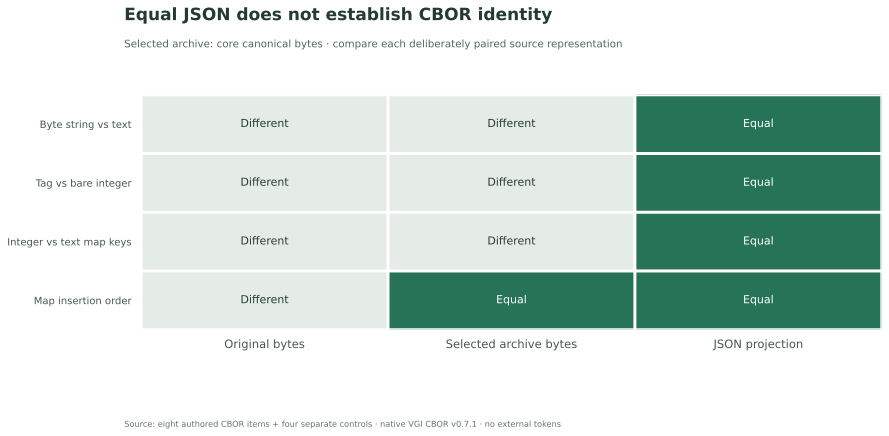

The **8 source items** contain **8 distinct original byte strings**. The selected archive has **7 distinct byte strings**, while the JSON view has only **4 distinct values**. JSON reconstruction changes **5 of eight core-normalized source encodings** even before choosing it as the archive. The selected archive differs from core-normalized source bytes in **0 rows**. These counts describe the authored cases, not every CBOR value or an application-wide equivalence rule.

In [15]:
example.identity_chart(pair_frame, summary, REBUILD_FROM_JSON)

## Byte counts cannot certify preservation

Measure lengths of the actual original and selected encodings. The bytes/text
pair can grow after reconstruction even as it loses the original type. Tags and
colliding map keys can shrink. No byte-count result repairs those distinctions;
retain the paired exact encodings and diagnostic output when evaluating the tradeoff.

In [16]:
%%sql sizes <<
SELECT id,label,octet_length(source) AS source_bytes,octet_length(archive) AS archive_bytes,
       core_bytes=archive AS preserves_core_bytes
FROM archived ORDER BY id;

,id,label,source_bytes,archive_bytes,preserves_core_bytes
0,1,Byte string,3,3,True
1,2,Text string,4,4,True
2,3,Epoch tag,2,2,True
3,4,Bare integer,1,1,True
4,5,Mixed key types,6,6,True
5,6,Collapsed text key,4,4,True
6,7,Integer key first,8,8,True
7,8,Text key first,8,8,True


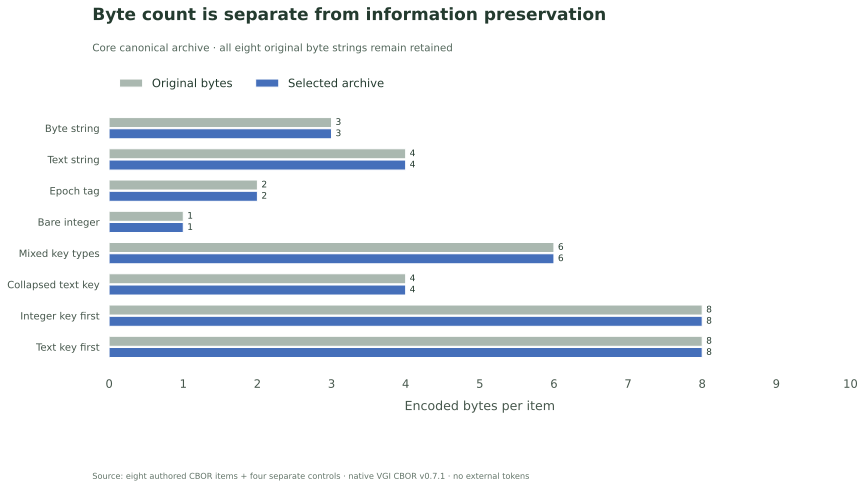

The selected archive contains **36 bytes** across these eight rows, compared with **36 original bytes**. A shorter or longer result is not evidence of preserved types. Even deterministic re-encoding can change original bytes; never replace signed input with normalized bytes and assume an existing signature still applies.

In [17]:
example.byte_chart(sizes, REBUILD_FROM_JSON)

## Check the retained population and defined comparisons

These checks reconcile all inputs, verify that the eight study items pass the
strict quality gate, and check canonical idempotence and JSON agreement. The
quality controls stay outside the study; NULL and parse failures never become
empty byte strings or manufactured records.

In [18]:
%%sql checks <<
SELECT 'All authored study rows retained' AS check_name,count(*)=8 AND count(DISTINCT id)=8 AS passed FROM archived
UNION ALL SELECT 'Study items pass both quality checks',bool_and(cbor.main.is_valid(source) AND cbor.main.well_formed(source).ok) FROM archived
UNION ALL SELECT 'Canonical encoding is idempotent',bool_and(cbor.main.canonical(core_bytes)=core_bytes) FROM archived
UNION ALL SELECT 'Struct mode remains the same JSON projection',bool_and(json_view=decode_struct) FROM archived
UNION ALL SELECT 'JSON reconstruction preserves only the JSON view',bool_and(cbor.main.to_json(json_rebuilt)=json_view) FROM archived
UNION ALL SELECT 'Paired original byte strings remain distinct',NOT bool_or(original_equal) FROM (SELECT a.source=b.source AS original_equal FROM samples a JOIN samples b ON a.pair_id=b.pair_id AND a.id<b.id)
UNION ALL SELECT 'Exactly four comparison pairs',count(*)=4 FROM (SELECT pair_id FROM archived GROUP BY pair_id HAVING count(*)=2)
UNION ALL SELECT 'Selected archive matches the requested branch',bool_and(archive=CASE WHEN {{ REBUILD_FROM_JSON }} THEN json_rebuilt ELSE core_bytes END) FROM archived;

In [19]:
example.identity_checks(checks)

,check_name,passed
0,All authored study rows retained,True
1,Study items pass both quality checks,True
2,Canonical encoding is idempotent,True
3,Struct mode remains the same JSON projection,True
4,JSON reconstruction preserves only the JSON view,True
5,Paired original byte strings remain distinct,True
6,Exactly four comparison pairs,True
7,Selected archive matches the requested branch,True


**All 8 relationship checks passed.** Original inputs stay retained; the archive choice changes only the explicitly selected derived representation.

## Experiment: rebuild from JSON

Change only **`REBUILD_FROM_JSON = True`**, restart and run all. Predict which
pair comparisons turn equal and whether each encoded length grows or shrinks.
The source bytes, diagnostic table, tag inspection, JSON views and quality
controls must remain unchanged. Reset to **False** for the saved default.

This is a representation choice for synthetic data, not a recommendation to
normalize signed input. A structurally decoded or canonically encoded value is
not authenticated. Preserve original bytes and apply the relevant verifier when
signatures or application-specific type distinctions matter.

In [20]:
con.execute("DETACH cbor")
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-cbor](https://github.com/Query-farm/vgi-cbor)
